In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from xgboost import XGBClassifier
import optuna
from sklearn.metrics import classification_report,accuracy_score, confusion_matrix
import joblib
import shap

In [ ]:
df = pd.read_csv('Dataset/heart.csv')

### Num cols

In [ ]:
num_cols = ['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']

### Cat cols

In [22]:
cat_cols = df.drop(columns=num_cols).columns
cat_cols

Index(['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina',
       'ST_Slope', 'HeartDisease'],
      dtype='str')

# Preliminary exploration

In [23]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [24]:
df.shape

(918, 12)

In [25]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


## nulls and duplicates

In [27]:
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [28]:
df.duplicated().sum()

np.int64(0)

# Data analysis

## Data Distribution

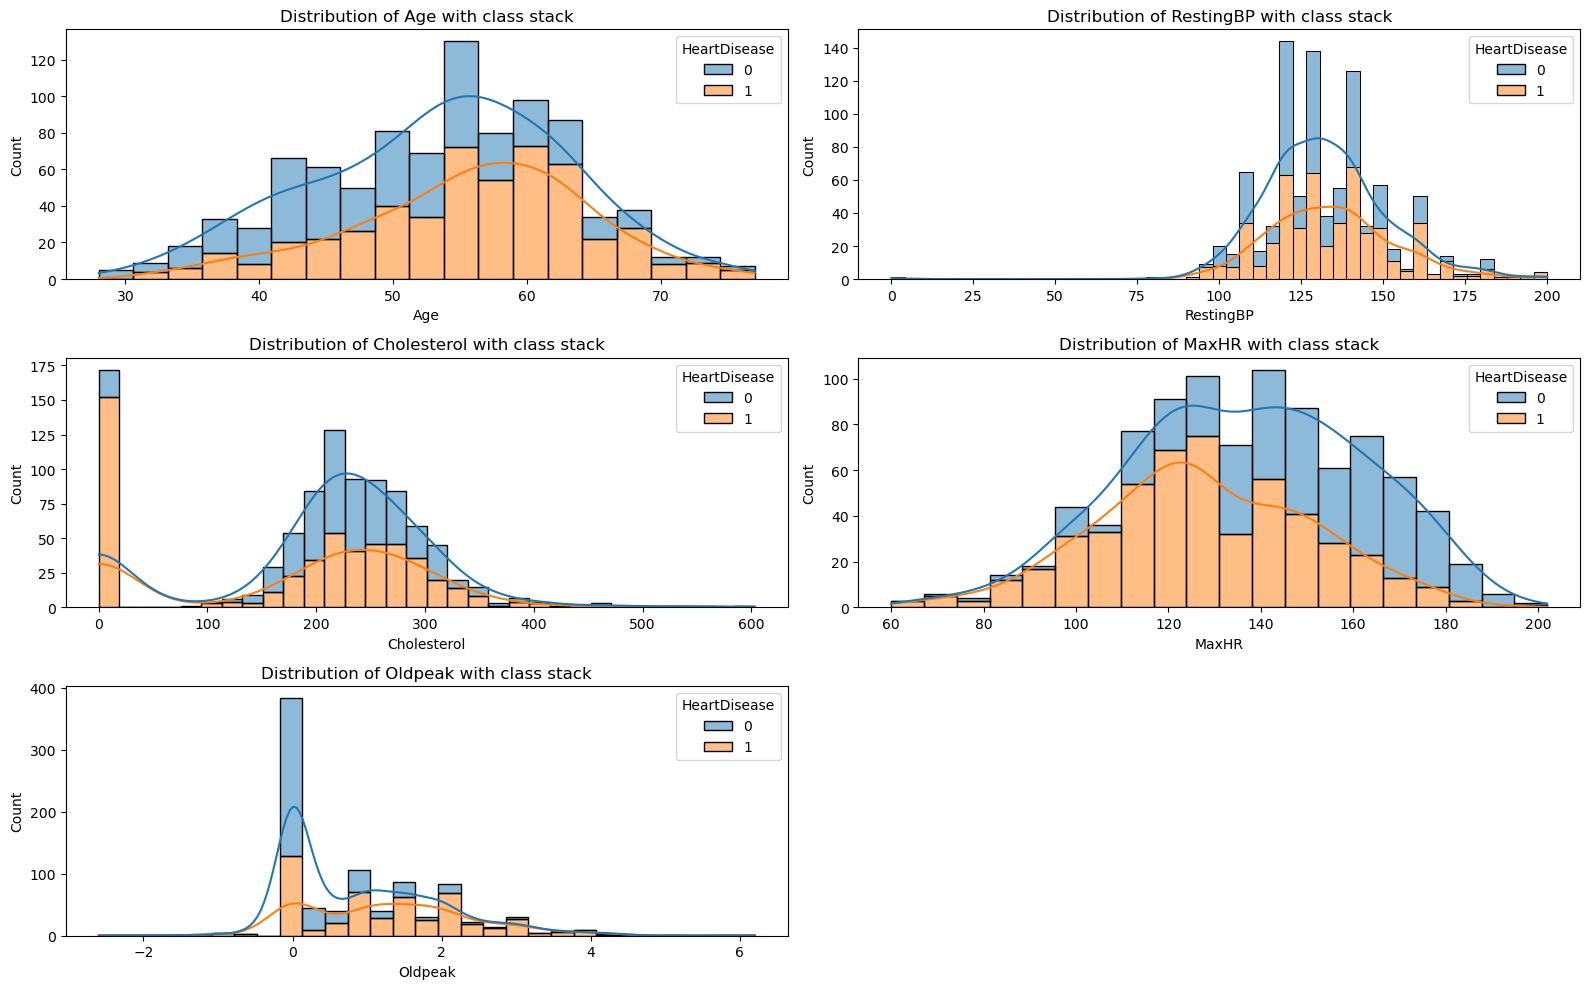

In [11]:
fig, axes = plt.subplots(3,2, figsize=(16,10))
for ax, col in zip(axes.flatten(),num_cols):
    sns.histplot(df, x=col, hue='HeartDisease',multiple='stack',ax=ax,kde=True)
    ax.set_title(f"Distribution of {col} with class stack")

axes[2,1].remove()
plt.tight_layout()
    

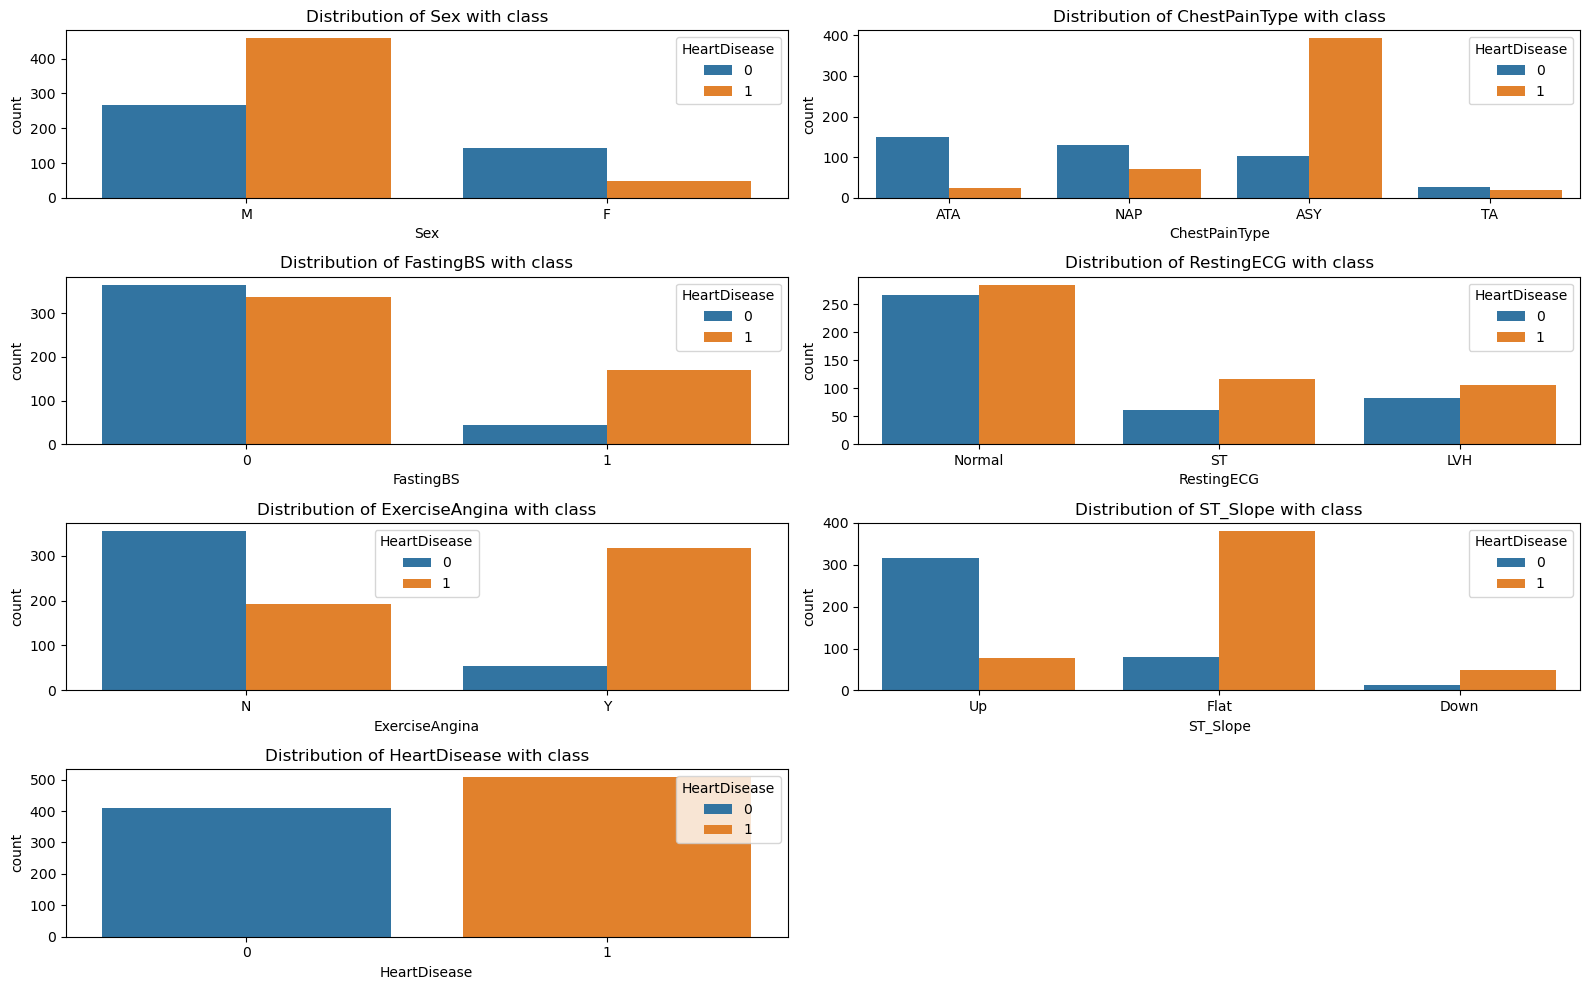

In [57]:
fig, axes = plt.subplots(4,2, figsize=(16,10))
for ax, col in zip(axes.flatten(),cat_cols):
    sns.countplot(df, x=col, hue='HeartDisease',ax=ax)
    ax.set_title(f"Distribution of {col} with class")

axes[3,1].remove()
plt.tight_layout()
    

# Correct cholestrol and restingbp data

In [29]:
df[df['RestingBP']<25]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


In [30]:
df = df.drop(449)

In [31]:
df[df['Cholesterol'] == 0]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
293,65,M,ASY,115,0,0,Normal,93,Y,0.0,Flat,1
294,32,M,TA,95,0,1,Normal,127,N,0.7,Up,1
295,61,M,ASY,105,0,1,Normal,110,Y,1.5,Up,1
296,50,M,ASY,145,0,1,Normal,139,Y,0.7,Flat,1
297,57,M,ASY,110,0,1,ST,131,Y,1.4,Up,1
...,...,...,...,...,...,...,...,...,...,...,...,...
514,43,M,ASY,122,0,0,Normal,120,N,0.5,Up,1
515,63,M,NAP,130,0,1,ST,160,N,3.0,Flat,0
518,48,M,NAP,102,0,1,ST,110,Y,1.0,Down,1
535,56,M,ASY,130,0,0,LVH,122,Y,1.0,Flat,1


In [32]:
df['Cholesterol'] = df['Cholesterol'].replace(0,np.nan)
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264.0,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193.0,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131.0,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236.0,0,LVH,174,N,0.0,Flat,1


# Imputation of NaN

### Data encoding

In [17]:
enc = OrdinalEncoder().set_output(transform='pandas')
enc_data = enc.fit_transform(df[cat_cols])
enc_data

,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope,HeartDisease
0,1.0,1.0,0.0,1.0,0.0,2.0,0.0
1,0.0,2.0,0.0,1.0,0.0,1.0,1.0
2,1.0,1.0,0.0,2.0,0.0,2.0,0.0
3,0.0,0.0,0.0,1.0,1.0,1.0,1.0
4,1.0,2.0,0.0,1.0,0.0,2.0,0.0
...,...,...,...,...,...,...,...
913,1.0,3.0,0.0,1.0,0.0,1.0,1.0
914,1.0,0.0,1.0,1.0,0.0,1.0,1.0
915,1.0,0.0,0.0,1.0,1.0,1.0,1.0
916,0.0,1.0,0.0,0.0,0.0,1.0,1.0


In [18]:
scalar = StandardScaler().set_output(transform='pandas')
scaled_data = scalar.fit_transform(df[num_cols])
scaled_data

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.432206,0.414627,0.750494,1.383339,-0.831502
1,-0.478057,1.526360,-1.093405,0.754736,0.106251
2,-1.750256,-0.141240,0.648995,-1.523953,-0.831502
3,-0.584074,0.303453,-0.518244,-1.131075,0.575128
4,0.052026,0.970493,-0.839657,-0.581047,-0.831502
...,...,...,...,...,...
913,-0.902124,-1.252973,0.327582,-0.188170,0.293802
914,1.536257,0.636973,-0.873490,0.165420,2.356860
915,0.370075,-0.141240,-1.922314,-0.856061,0.293802
916,0.370075,-0.141240,-0.146081,1.461915,-0.831502


In [19]:
enc_df = pd.concat([scaled_data,enc_data],axis=1)
enc_df

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope,HeartDisease
0,-1.432206,0.414627,0.750494,1.383339,-0.831502,1.0,1.0,0.0,1.0,0.0,2.0,0.0
1,-0.478057,1.526360,-1.093405,0.754736,0.106251,0.0,2.0,0.0,1.0,0.0,1.0,1.0
2,-1.750256,-0.141240,0.648995,-1.523953,-0.831502,1.0,1.0,0.0,2.0,0.0,2.0,0.0
3,-0.584074,0.303453,-0.518244,-1.131075,0.575128,0.0,0.0,0.0,1.0,1.0,1.0,1.0
4,0.052026,0.970493,-0.839657,-0.581047,-0.831502,1.0,2.0,0.0,1.0,0.0,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902124,-1.252973,0.327582,-0.188170,0.293802,1.0,3.0,0.0,1.0,0.0,1.0,1.0
914,1.536257,0.636973,-0.873490,0.165420,2.356860,1.0,0.0,1.0,1.0,0.0,1.0,1.0
915,0.370075,-0.141240,-1.922314,-0.856061,0.293802,1.0,0.0,0.0,1.0,1.0,1.0,1.0
916,0.370075,-0.141240,-0.146081,1.461915,-0.831502,0.0,1.0,0.0,0.0,0.0,1.0,1.0


## KNNImputation

In [20]:
imputer = KNNImputer().set_output(transform='pandas')
scaled_imputed = imputer.fit_transform(enc_df)

descaled_num_imputed = pd.DataFrame(scalar.inverse_transform(scaled_imputed[num_cols]),index=scaled_imputed.index,columns=num_cols)
imputed_cat = pd.DataFrame(enc.inverse_transform(scaled_imputed[cat_cols]),index=scaled_imputed.index,columns=cat_cols)

final_df = pd.concat([descaled_num_imputed,imputed_cat],axis=1)
final_df

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope,HeartDisease
0,40.0,140.0,289.0,172.0,0.0,M,ATA,0,Normal,N,Up,0
1,49.0,160.0,180.0,156.0,1.0,F,NAP,0,Normal,N,Flat,1
2,37.0,130.0,283.0,98.0,0.0,M,ATA,0,ST,N,Up,0
3,48.0,138.0,214.0,108.0,1.5,F,ASY,0,Normal,Y,Flat,1
4,54.0,150.0,195.0,122.0,0.0,M,NAP,0,Normal,N,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45.0,110.0,264.0,132.0,1.2,M,TA,0,Normal,N,Flat,1
914,68.0,144.0,193.0,141.0,3.4,M,ASY,1,Normal,N,Flat,1
915,57.0,130.0,131.0,115.0,1.2,M,ASY,0,Normal,Y,Flat,1
916,57.0,130.0,236.0,174.0,0.0,F,ATA,0,LVH,N,Flat,1


In [21]:
final_df.isna().sum(
)

Age               0
RestingBP         0
Cholesterol       0
MaxHR             0
Oldpeak           0
Sex               0
ChestPainType     0
FastingBS         0
RestingECG        0
ExerciseAngina    0
ST_Slope          0
HeartDisease      0
dtype: int64

# Imputation pipeline

In [33]:
prep = ColumnTransformer([
    ('scalar', StandardScaler(),num_cols),
    ('encoder',OrdinalEncoder(),cat_cols)
])
prep_imp = Pipeline([('prep',prep),('imputer',KNNImputer())])
p_df=pd.DataFrame(prep_imp.fit_transform(df),index=df.index,columns=num_cols+list(cat_cols))
p_df

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope,HeartDisease
0,-1.432206,0.414627,0.750494,1.383339,-0.831502,1.0,1.0,0.0,1.0,0.0,2.0,0.0
1,-0.478057,1.526360,-1.093405,0.754736,0.106251,0.0,2.0,0.0,1.0,0.0,1.0,1.0
2,-1.750256,-0.141240,0.648995,-1.523953,-0.831502,1.0,1.0,0.0,2.0,0.0,2.0,0.0
3,-0.584074,0.303453,-0.518244,-1.131075,0.575128,0.0,0.0,0.0,1.0,1.0,1.0,1.0
4,0.052026,0.970493,-0.839657,-0.581047,-0.831502,1.0,2.0,0.0,1.0,0.0,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902124,-1.252973,0.327582,-0.188170,0.293802,1.0,3.0,0.0,1.0,0.0,1.0,1.0
914,1.536257,0.636973,-0.873490,0.165420,2.356860,1.0,0.0,1.0,1.0,0.0,1.0,1.0
915,0.370075,-0.141240,-1.922314,-0.856061,0.293802,1.0,0.0,0.0,1.0,1.0,1.0,1.0
916,0.370075,-0.141240,-0.146081,1.461915,-0.831502,0.0,1.0,0.0,0.0,0.0,1.0,1.0


In [34]:
scalar = prep.named_transformers_['scalar']
encoder = prep.named_transformers_['encoder']
num_imp = pd.DataFrame(scalar.inverse_transform(p_df[num_cols]),index=df.index,columns=num_cols)
cat_imp = pd.DataFrame(encoder.inverse_transform(p_df[cat_cols]),index=df.index,columns=cat_cols)
final_df = pd.concat([num_imp,cat_imp],axis=1)

<Axes: xlabel='Cholesterol', ylabel='Count'>

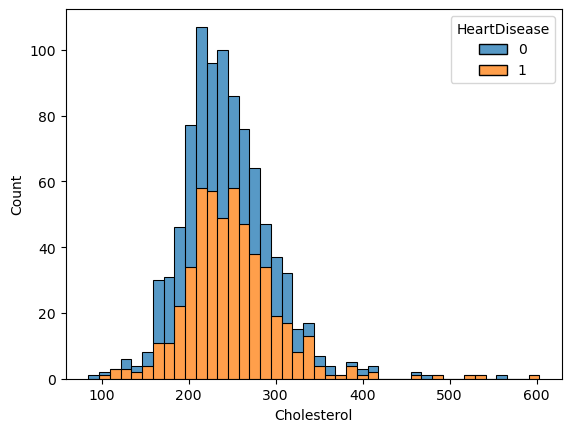

In [35]:
sns.histplot(final_df,x='Cholesterol', hue='HeartDisease', multiple='stack')

## Correlation

Text(0.5, 1.0, 'Correlation matrix')

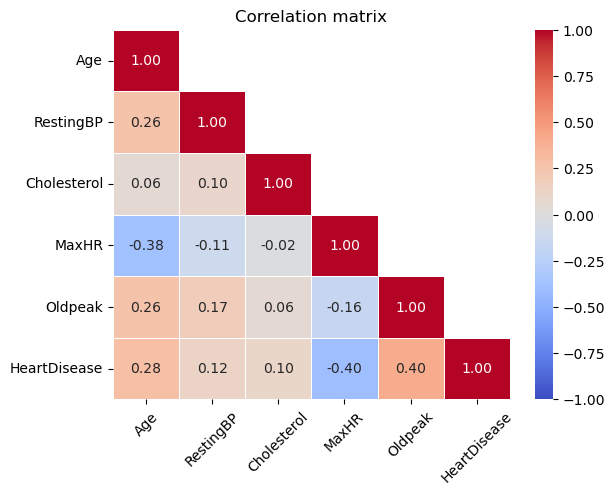

In [25]:
corr = df[num_cols+['HeartDisease']].corr()
mask = np.triu(np.ones_like(corr,dtype=bool),k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', linewidth=.5, center=0, vmax=1,vmin=-1,cmap='coolwarm')
plt.xticks(rotation=45)
plt.title("Correlation matrix")

# Preprocessing

## Outliers 

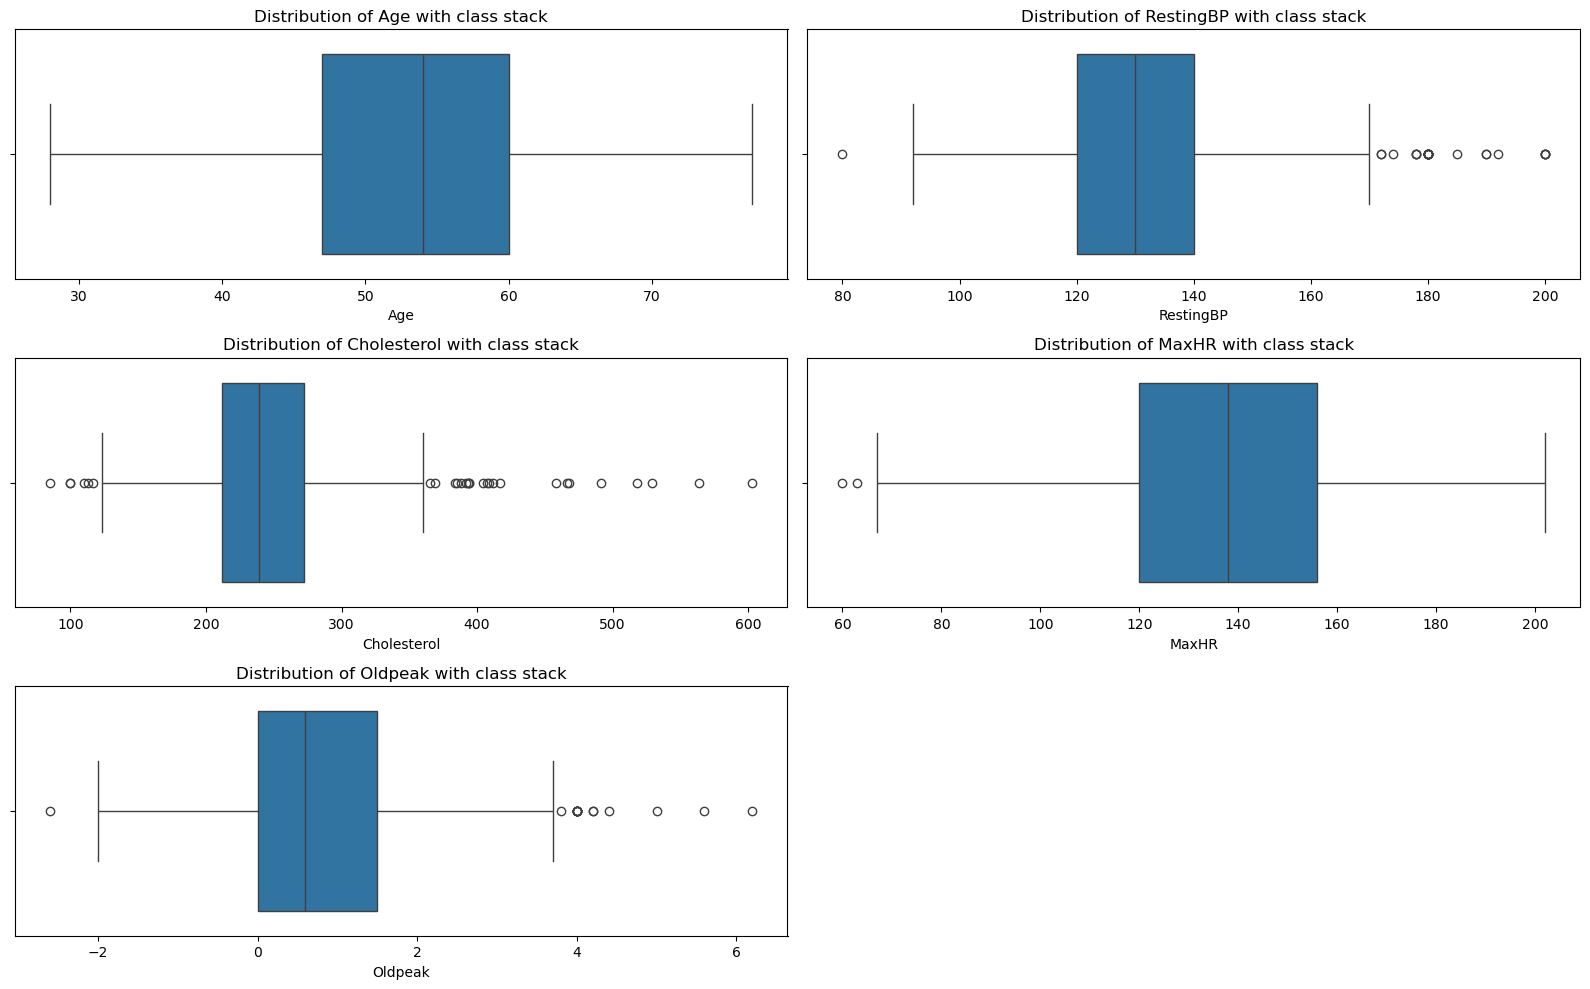

In [26]:
fig, axes = plt.subplots(3,2, figsize=(16,10))
for ax, col in zip(axes.flatten(),num_cols):
    sns.boxplot(final_df, x=col,ax=ax)
    ax.set_title(f"Distribution of {col} with class stack")

axes[2,1].remove()
plt.tight_layout()
    

# Training

In [36]:
final_df['FastingBS'] = pd.to_numeric(final_df['FastingBS'])
final_df['HeartDisease'] = pd.to_numeric(final_df['HeartDisease'])

In [37]:
cat_cols = list(cat_cols)
cat_cols.remove('HeartDisease')

In [38]:
X = final_df.drop(columns=['HeartDisease'])
y = final_df['HeartDisease']


In [39]:
X.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'Sex',
       'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina',
       'ST_Slope'],
      dtype='str')

## train pipeline

In [40]:
def train_pipeline(model,scoring=None):
    train_pipe = Pipeline([
    ('prep',ColumnTransformer([
    ('scalar',StandardScaler(),num_cols),
    ('encoder',OneHotEncoder(),cat_cols)
])),
    ('model',model())
                      ])
    res = cross_validate(train_pipe,X,y,cv=5,error_score='raise',return_train_score=True,return_estimator=True,scoring=scoring)
    return res,train_pipe
    

## Hyperpara tuning

In [41]:
def hyper_tune(train_pipe,n_trials=100):
    def objective(trial):
        params = {
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 200, 800),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
    }
        train_pipe.set_params(**{f'model__{k}':v for k,v in params.items()})
        res = cross_validate(train_pipe,X,y,n_jobs=-1,cv=5,return_train_score=True,error_score='raise')
        print('Train Score:',res['train_score'].mean())
        return res['test_score'].mean()
    
    study = optuna.create_study(direction='maximize')  
    study.optimize(objective, n_trials=n_trials) 
    print(study.best_value,study.best_params)


## W/O oulier removal

### Logistic Regression

In [33]:
res,train_pipe = train_pipeline(LogisticRegression)

In [34]:
res['train_score'].mean(),res['test_score'].mean()

(np.float64(0.869678563330124), np.float64(0.8374376336421951))

In [35]:
cols = list(res['estimator'][0]['prep']['encoder'].get_feature_names_out())

In [36]:
coeffs = [est['model'].coef_[0] for est in res['estimator']]
pd.DataFrame(coeffs, columns=num_cols+cols).agg(['mean','std']).T

,mean,std
Age,0.179366,0.099976
RestingBP,0.041570,0.069956
Cholesterol,0.148687,0.048909
MaxHR,-0.231690,0.131222
Oldpeak,0.385671,0.053894
Sex_F,-0.798680,0.059970
Sex_M,0.769046,0.069428
ChestPainType_ASY,1.164607,0.148676
ChestPainType_ATA,-0.651066,0.164495
ChestPainType_NAP,-0.365249,0.093554


### XGBOOST

In [45]:
res,train_pipe = train_pipeline(XGBClassifier)
res['test_score'].mean(),res['train_score'].mean()

(np.float64(0.816720123544785), np.float64(1.0))

In [46]:
explainer_xgb = shap.Explainer(train_pipe.named_steps['model'], X)
shap_values_xgb = explainer_xgb(prep_series)
shap.plots.waterfall(shap_values_xgb[0], max_display=14)

X_shap = train_pipe.named_steps['prep'].transform(X)

TypeError: The passed model is not callable and cannot be analyzed directly with the given masker! Model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [24]:
hyper_tune(train_pipe)

[I 2026-10-07 21:00:50,333] A new study created in memory with name: no-name-c6e7b885-c889-495e-b21c-428d515639dc
[I 2026-10-07 21:00:53,434] Trial 0 finished with value: 0.8395937277263009 and parameters: {'max_depth': 6, 'learning_rate': 0.014719421747888503, 'n_estimators': 625, 'subsample': 0.9952856048927211, 'colsample_bytree': 0.6268076014260202, 'min_child_weight': 4, 'gamma': 4.920528575924336, 'reg_lambda': 0.016041354722637766, 'reg_alpha': 0.013167753951834393}. Best is trial 0 with value: 0.8395937277263009.


Train Score: 0.8933969242893414


[I 2026-10-07 21:00:59,266] Trial 1 finished with value: 0.8417973390354003 and parameters: {'max_depth': 4, 'learning_rate': 0.010767498485845121, 'n_estimators': 612, 'subsample': 0.94749760489617, 'colsample_bytree': 0.7557397152575269, 'min_child_weight': 9, 'gamma': 2.137927399438591, 'reg_lambda': 0.07506309753562641, 'reg_alpha': 0.0046908407745373795}. Best is trial 1 with value: 0.8417973390354003.


Train Score: 0.8993959354821921


[I 2026-10-07 21:01:05,064] Trial 2 finished with value: 0.8385245901639344 and parameters: {'max_depth': 7, 'learning_rate': 0.08994101143943982, 'n_estimators': 201, 'subsample': 0.6781048808490475, 'colsample_bytree': 0.7595800018328233, 'min_child_weight': 8, 'gamma': 3.6742875617837356, 'reg_lambda': 2.025372640858166, 'reg_alpha': 5.096840648480565}. Best is trial 1 with value: 0.8417973390354003.


Train Score: 0.8737683589146912


[I 2026-10-07 21:01:11,098] Trial 3 finished with value: 0.8396115466856736 and parameters: {'max_depth': 4, 'learning_rate': 0.021723354907487342, 'n_estimators': 621, 'subsample': 0.6961115314678925, 'colsample_bytree': 0.5527621454788276, 'min_child_weight': 3, 'gamma': 1.8626086313891403, 'reg_lambda': 0.14716406020585834, 'reg_alpha': 0.0025692995465556308}. Best is trial 1 with value: 0.8417973390354003.


Train Score: 0.9203883856050495


[I 2026-10-07 21:01:11,360] Trial 4 finished with value: 0.8472499406034688 and parameters: {'max_depth': 3, 'learning_rate': 0.02339367954045553, 'n_estimators': 351, 'subsample': 0.6614349988816671, 'colsample_bytree': 0.9992427488863612, 'min_child_weight': 9, 'gamma': 1.3972422413365777, 'reg_lambda': 0.8191306020861239, 'reg_alpha': 0.1923274746612388}. Best is trial 4 with value: 0.8472499406034688.


Train Score: 0.8999397794142248


[I 2026-10-07 21:01:11,684] Trial 5 finished with value: 0.8439712520788787 and parameters: {'max_depth': 7, 'learning_rate': 0.01638067457983632, 'n_estimators': 695, 'subsample': 0.7768293862162066, 'colsample_bytree': 0.6361431628691492, 'min_child_weight': 4, 'gamma': 3.060641364082702, 'reg_lambda': 1.5190168001196824, 'reg_alpha': 0.005560222002188913}. Best is trial 4 with value: 0.8472499406034688.


Train Score: 0.9021203593905082
Train Score: 0.8890339056767196


[I 2026-10-07 21:01:11,888] Trial 6 finished with value: 0.8418032786885246 and parameters: {'max_depth': 4, 'learning_rate': 0.09988784244562185, 'n_estimators': 407, 'subsample': 0.9884105554520931, 'colsample_bytree': 0.9858745193786623, 'min_child_weight': 10, 'gamma': 4.977126438646516, 'reg_lambda': 1.5920395298698142, 'reg_alpha': 0.002157893356931796}. Best is trial 4 with value: 0.8472499406034688.
[I 2026-10-07 21:01:12,192] Trial 7 finished with value: 0.8515858873841768 and parameters: {'max_depth': 5, 'learning_rate': 0.011687988631181975, 'n_estimators': 378, 'subsample': 0.8500397964808404, 'colsample_bytree': 0.9985313870871622, 'min_child_weight': 3, 'gamma': 2.0785097387527545, 'reg_lambda': 0.01174743844611599, 'reg_alpha': 0.011433176174403013}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9236611142295297


[I 2026-10-07 21:01:12,599] Trial 8 finished with value: 0.8396353052981705 and parameters: {'max_depth': 7, 'learning_rate': 0.020579349716786502, 'n_estimators': 703, 'subsample': 0.7176539262852986, 'colsample_bytree': 0.9670879075901108, 'min_child_weight': 7, 'gamma': 0.33842086280562733, 'reg_lambda': 0.042118921311028804, 'reg_alpha': 0.40438587506224255}. Best is trial 7 with value: 0.8515858873841768.
[I 2026-10-07 21:01:12,762] Trial 9 finished with value: 0.8232299833689712 and parameters: {'max_depth': 5, 'learning_rate': 0.019330634036658446, 'n_estimators': 234, 'subsample': 0.6571027113887657, 'colsample_bytree': 0.9373014674902533, 'min_child_weight': 13, 'gamma': 3.9139351076275686, 'reg_lambda': 0.052903893881014304, 'reg_alpha': 6.19208469061369}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9261145455018568
Train Score: 0.8650438086174915


[I 2026-10-07 21:01:12,985] Trial 10 finished with value: 0.8406806842480398 and parameters: {'max_depth': 4, 'learning_rate': 0.18573795461693224, 'n_estimators': 391, 'subsample': 0.8282750556736569, 'colsample_bytree': 0.9868529848711658, 'min_child_weight': 1, 'gamma': 2.359230524269923, 'reg_lambda': 0.2889975943331246, 'reg_alpha': 0.020952661581595675}. Best is trial 7 with value: 0.8515858873841768.
[I 2026-10-07 21:01:13,177] Trial 11 finished with value: 0.8450582086006178 and parameters: {'max_depth': 3, 'learning_rate': 0.0331417052752301, 'n_estimators': 252, 'subsample': 0.8070181848122926, 'colsample_bytree': 0.9953938507391851, 'min_child_weight': 10, 'gamma': 1.8363706145181622, 'reg_lambda': 1.3101778736843734, 'reg_alpha': 0.03172011194699828}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9334737241228053
Train Score: 0.8963964298857668


[I 2026-10-07 21:01:13,397] Trial 12 finished with value: 0.8374316939890709 and parameters: {'max_depth': 4, 'learning_rate': 0.011264154584651331, 'n_estimators': 339, 'subsample': 0.6363992571231842, 'colsample_bytree': 0.9327082638359228, 'min_child_weight': 12, 'gamma': 1.2114289368943485, 'reg_lambda': 0.4759382782948497, 'reg_alpha': 0.5017983391956509}. Best is trial 7 with value: 0.8515858873841768.
[I 2026-10-07 21:01:13,596] Trial 13 finished with value: 0.8428842955571394 and parameters: {'max_depth': 5, 'learning_rate': 0.020080952133163698, 'n_estimators': 225, 'subsample': 0.7588296619961967, 'colsample_bytree': 0.9855180428996638, 'min_child_weight': 8, 'gamma': 1.75172789269998, 'reg_lambda': 0.014940911146146447, 'reg_alpha': 0.08809513231516974}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8778574110352364
Train Score: 0.9007587050343666


[I 2026-10-07 21:01:13,846] Trial 14 finished with value: 0.8428902352102637 and parameters: {'max_depth': 3, 'learning_rate': 0.021418756079884513, 'n_estimators': 380, 'subsample': 0.7657593438349545, 'colsample_bytree': 0.8370662833714271, 'min_child_weight': 4, 'gamma': 1.3662363241732833, 'reg_lambda': 3.876057935865304, 'reg_alpha': 0.9643024893807814}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8985770098620502


[I 2026-10-07 21:01:14,085] Trial 15 finished with value: 0.8428605369446425 and parameters: {'max_depth': 5, 'learning_rate': 0.021046700342138774, 'n_estimators': 245, 'subsample': 0.8772435643805674, 'colsample_bytree': 0.9687248847335039, 'min_child_weight': 3, 'gamma': 1.325972000463111, 'reg_lambda': 0.016751751124819757, 'reg_alpha': 0.006473427740220855}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9337484340789037


[I 2026-10-07 21:01:14,384] Trial 16 finished with value: 0.8417795200760276 and parameters: {'max_depth': 5, 'learning_rate': 0.01153166902112532, 'n_estimators': 354, 'subsample': 0.7399386922816733, 'colsample_bytree': 0.8762520596816439, 'min_child_weight': 1, 'gamma': 2.0265941707052555, 'reg_lambda': 0.010961338960929297, 'reg_alpha': 0.22546154376279198}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9310228949745548


[I 2026-10-07 21:01:14,651] Trial 17 finished with value: 0.8439890710382514 and parameters: {'max_depth': 4, 'learning_rate': 0.03432666245635402, 'n_estimators': 431, 'subsample': 0.7166503354936327, 'colsample_bytree': 0.961541929822515, 'min_child_weight': 8, 'gamma': 1.043191038434786, 'reg_lambda': 1.1809172009021032, 'reg_alpha': 0.42270844320365614}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9097538762355443


[I 2026-10-07 21:01:14,857] Trial 18 finished with value: 0.8396115466856736 and parameters: {'max_depth': 5, 'learning_rate': 0.020104162766347407, 'n_estimators': 227, 'subsample': 0.8981729059664671, 'colsample_bytree': 0.9788513132686468, 'min_child_weight': 11, 'gamma': 1.7792197750510983, 'reg_lambda': 0.09079990150819178, 'reg_alpha': 0.05720690760442891}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8985777533260721


[I 2026-10-07 21:01:15,158] Trial 19 finished with value: 0.8450641482537421 and parameters: {'max_depth': 4, 'learning_rate': 0.01729548218827692, 'n_estimators': 526, 'subsample': 0.7283760635610745, 'colsample_bytree': 0.9710728948335198, 'min_child_weight': 10, 'gamma': 1.2949562155485181, 'reg_lambda': 0.011836117963694888, 'reg_alpha': 0.16498525895517333}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9032125080387049


[I 2026-10-07 21:01:15,461] Trial 20 finished with value: 0.8417854597291518 and parameters: {'max_depth': 5, 'learning_rate': 0.01783451139040021, 'n_estimators': 410, 'subsample': 0.7826440221271054, 'colsample_bytree': 0.9621675975669287, 'min_child_weight': 4, 'gamma': 0.9847304363455479, 'reg_lambda': 0.10448996960537875, 'reg_alpha': 0.05076141401604519}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9375650066354163


[I 2026-10-07 21:01:15,685] Trial 21 finished with value: 0.840710382513661 and parameters: {'max_depth': 3, 'learning_rate': 0.042680814934914824, 'n_estimators': 356, 'subsample': 0.6443541629342439, 'colsample_bytree': 0.9957357110007831, 'min_child_weight': 8, 'gamma': 1.271562300998661, 'reg_lambda': 0.10797432640891075, 'reg_alpha': 0.12043150576991304}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9113898688157732


[I 2026-10-07 21:01:15,983] Trial 22 finished with value: 0.8472558802565929 and parameters: {'max_depth': 5, 'learning_rate': 0.01908081576891029, 'n_estimators': 520, 'subsample': 0.7756462598129027, 'colsample_bytree': 0.9264068167387147, 'min_child_weight': 12, 'gamma': 1.3857294313652817, 'reg_lambda': 0.027537962087921627, 'reg_alpha': 0.017283878836821354}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8958503555616686


[I 2026-10-07 21:01:16,198] Trial 23 finished with value: 0.8341411261582323 and parameters: {'max_depth': 4, 'learning_rate': 0.010232617615040823, 'n_estimators': 227, 'subsample': 0.79744356275964, 'colsample_bytree': 0.8467888096099414, 'min_child_weight': 2, 'gamma': 1.9365666083885185, 'reg_lambda': 0.018249851715370326, 'reg_alpha': 0.0249218433994072}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9094821401355336


[I 2026-10-07 21:01:16,443] Trial 24 finished with value: 0.837407935376574 and parameters: {'max_depth': 5, 'learning_rate': 0.012569292277660649, 'n_estimators': 225, 'subsample': 0.9506525909128664, 'colsample_bytree': 0.9246976925741528, 'min_child_weight': 1, 'gamma': 2.373206512117302, 'reg_lambda': 0.013106362308604253, 'reg_alpha': 0.050838215544041054}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9288393411421838


[I 2026-10-07 21:01:16,736] Trial 25 finished with value: 0.8406985032074127 and parameters: {'max_depth': 7, 'learning_rate': 0.014802435737987632, 'n_estimators': 481, 'subsample': 0.8586037281298154, 'colsample_bytree': 0.9804278176749304, 'min_child_weight': 9, 'gamma': 2.2488704827593504, 'reg_lambda': 0.023757435572915965, 'reg_alpha': 0.01896051881953258}. Best is trial 7 with value: 0.8515858873841768.
[I 2026-10-07 21:01:16,934] Trial 26 finished with value: 0.8417913993822761 and parameters: {'max_depth': 3, 'learning_rate': 0.04483294207604756, 'n_estimators': 267, 'subsample': 0.7212254158724948, 'colsample_bytree': 0.9354918904794273, 'min_child_weight': 8, 'gamma': 1.4006172394047764, 'reg_lambda': 0.03963253747328053, 'reg_alpha': 0.0754843924177598}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9007594484983885
Train Score: 0.9089353223474133


[I 2026-10-07 21:01:17,203] Trial 27 finished with value: 0.8461451651223568 and parameters: {'max_depth': 3, 'learning_rate': 0.010910031390924847, 'n_estimators': 467, 'subsample': 0.9350741982048381, 'colsample_bytree': 0.9634303915360456, 'min_child_weight': 6, 'gamma': 2.669500598403068, 'reg_lambda': 0.03672176896134606, 'reg_alpha': 0.00152425838701362}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8991189951340279


[I 2026-10-07 21:01:17,419] Trial 28 finished with value: 0.8406925635542883 and parameters: {'max_depth': 5, 'learning_rate': 0.012968596739301912, 'n_estimators': 316, 'subsample': 0.8312659962150499, 'colsample_bytree': 0.9340195402344745, 'min_child_weight': 13, 'gamma': 2.436287059261712, 'reg_lambda': 0.01392454945383891, 'reg_alpha': 0.04485345344036035}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8876729947845998


[I 2026-10-07 21:01:17,697] Trial 29 finished with value: 0.8406866239011641 and parameters: {'max_depth': 5, 'learning_rate': 0.0298740575306827, 'n_estimators': 431, 'subsample': 0.8067876230620663, 'colsample_bytree': 0.9719423207627365, 'min_child_weight': 7, 'gamma': 1.3182283497671559, 'reg_lambda': 0.014581457483250087, 'reg_alpha': 0.007433331103780828}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9214805342532462


[I 2026-10-07 21:01:18,042] Trial 30 finished with value: 0.8439474934663818 and parameters: {'max_depth': 5, 'learning_rate': 0.012269506591638769, 'n_estimators': 540, 'subsample': 0.8704356278453244, 'colsample_bytree': 0.9010080128196011, 'min_child_weight': 3, 'gamma': 2.1468974223002997, 'reg_lambda': 0.013966798085840781, 'reg_alpha': 0.01635819682945051}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9233882629334861


[I 2026-10-07 21:01:18,327] Trial 31 finished with value: 0.8439534331195058 and parameters: {'max_depth': 8, 'learning_rate': 0.017795100281686776, 'n_estimators': 425, 'subsample': 0.8352553081908258, 'colsample_bytree': 0.939990487895114, 'min_child_weight': 3, 'gamma': 2.372865410524965, 'reg_lambda': 0.01730399134146817, 'reg_alpha': 0.0040290409537799745}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9222972294813223


[I 2026-10-07 21:01:18,644] Trial 32 finished with value: 0.8428605369446425 and parameters: {'max_depth': 6, 'learning_rate': 0.011337486674524491, 'n_estimators': 348, 'subsample': 0.7873019183364116, 'colsample_bytree': 0.9819704350291396, 'min_child_weight': 3, 'gamma': 1.4451879912239196, 'reg_lambda': 0.02222173783908879, 'reg_alpha': 0.004938704783203797}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9312942593425548


[I 2026-10-07 21:01:18,922] Trial 33 finished with value: 0.8428664765977667 and parameters: {'max_depth': 3, 'learning_rate': 0.01393379030131498, 'n_estimators': 510, 'subsample': 0.9736250973710427, 'colsample_bytree': 0.9324833283688626, 'min_child_weight': 7, 'gamma': 2.704025349169403, 'reg_lambda': 0.023783448873638226, 'reg_alpha': 0.00587866726773932}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.8985732925419407


[I 2026-10-07 21:01:19,163] Trial 34 finished with value: 0.847232121644096 and parameters: {'max_depth': 3, 'learning_rate': 0.014621760854029067, 'n_estimators': 362, 'subsample': 0.8968140834878279, 'colsample_bytree': 0.9885343994777981, 'min_child_weight': 3, 'gamma': 2.842145387969735, 'reg_lambda': 0.021040100775641793, 'reg_alpha': 0.005472971049775715}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9051187497909007


[I 2026-10-07 21:01:19,426] Trial 35 finished with value: 0.8450522689474933 and parameters: {'max_depth': 3, 'learning_rate': 0.011490747086255478, 'n_estimators': 393, 'subsample': 0.8754989320347181, 'colsample_bytree': 0.9273716677064877, 'min_child_weight': 3, 'gamma': 2.5940772279430417, 'reg_lambda': 0.022147962149464375, 'reg_alpha': 0.023347752092152854}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9045741623948462


[I 2026-10-07 21:01:19,793] Trial 36 finished with value: 0.8428664765977667 and parameters: {'max_depth': 4, 'learning_rate': 0.013387411259392466, 'n_estimators': 494, 'subsample': 0.8679447449796521, 'colsample_bytree': 0.9617283186000103, 'min_child_weight': 5, 'gamma': 1.0520697361667593, 'reg_lambda': 0.0147314741906237, 'reg_alpha': 0.007704559044334737}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9231157833694532


[I 2026-10-07 21:01:20,066] Trial 37 finished with value: 0.8428605369446425 and parameters: {'max_depth': 3, 'learning_rate': 0.010808103503758337, 'n_estimators': 303, 'subsample': 0.9263247464408049, 'colsample_bytree': 0.8807861297163485, 'min_child_weight': 6, 'gamma': 2.0200949218069493, 'reg_lambda': 0.011939486644705519, 'reg_alpha': 0.011385487074656543}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.892031180881079


[I 2026-10-07 21:01:20,360] Trial 38 finished with value: 0.8461570444286053 and parameters: {'max_depth': 5, 'learning_rate': 0.02116743672694754, 'n_estimators': 307, 'subsample': 0.8132513481679692, 'colsample_bytree': 0.9928847835870854, 'min_child_weight': 1, 'gamma': 2.347930675559589, 'reg_lambda': 0.01742267758849386, 'reg_alpha': 0.0017513912259880646}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.934565501038991


[I 2026-10-07 21:01:20,657] Trial 39 finished with value: 0.8450582086006178 and parameters: {'max_depth': 4, 'learning_rate': 0.024349142892000547, 'n_estimators': 378, 'subsample': 0.8444417963716672, 'colsample_bytree': 0.8794978141855242, 'min_child_weight': 3, 'gamma': 2.27730259313891, 'reg_lambda': 0.011636065919110272, 'reg_alpha': 0.005615682842901384}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.920115534309006


[I 2026-10-07 21:01:21,007] Trial 40 finished with value: 0.8439712520788787 and parameters: {'max_depth': 7, 'learning_rate': 0.018650921132735622, 'n_estimators': 623, 'subsample': 0.801642132133215, 'colsample_bytree': 0.9802240950531442, 'min_child_weight': 4, 'gamma': 1.7855522951400307, 'reg_lambda': 0.016901189367808357, 'reg_alpha': 0.024492710624381943}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.926931612461944


[I 2026-10-07 21:01:21,272] Trial 41 finished with value: 0.8450344499881208 and parameters: {'max_depth': 6, 'learning_rate': 0.01667804729156964, 'n_estimators': 315, 'subsample': 0.9066240709180529, 'colsample_bytree': 0.9672003498522693, 'min_child_weight': 3, 'gamma': 2.2152617859864914, 'reg_lambda': 0.010108676871173995, 'reg_alpha': 0.005682615543576812}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9242064450896061


[I 2026-10-07 21:01:21,514] Trial 42 finished with value: 0.8385067712045616 and parameters: {'max_depth': 4, 'learning_rate': 0.010022677075941405, 'n_estimators': 254, 'subsample': 0.855239332052755, 'colsample_bytree': 0.991559931911101, 'min_child_weight': 2, 'gamma': 2.393624275708062, 'reg_lambda': 0.02278701517331535, 'reg_alpha': 0.0052940687136382595}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9108463966157517


[I 2026-10-07 21:01:21,752] Trial 43 finished with value: 0.8417735804229032 and parameters: {'max_depth': 6, 'learning_rate': 0.03199219285129635, 'n_estimators': 291, 'subsample': 0.823054465349222, 'colsample_bytree': 0.9444610968766239, 'min_child_weight': 1, 'gamma': 1.859916599000576, 'reg_lambda': 0.022521793527797398, 'reg_alpha': 0.004273507734464912}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9506510886171942


[I 2026-10-07 21:01:21,994] Trial 44 finished with value: 0.8450522689474933 and parameters: {'max_depth': 5, 'learning_rate': 0.023128461903218434, 'n_estimators': 316, 'subsample': 0.8272531893513795, 'colsample_bytree': 0.8679303339087443, 'min_child_weight': 3, 'gamma': 2.779870124400712, 'reg_lambda': 0.011893361950038943, 'reg_alpha': 0.014039775097089365}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9163008204125482


[I 2026-10-07 21:01:22,265] Trial 45 finished with value: 0.8450463292943692 and parameters: {'max_depth': 6, 'learning_rate': 0.02559996429804948, 'n_estimators': 392, 'subsample': 0.8373831411939205, 'colsample_bytree': 0.9935809428335891, 'min_child_weight': 3, 'gamma': 1.6866453341405045, 'reg_lambda': 0.011039666064791355, 'reg_alpha': 0.002055047063952211}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9348383523350347


[I 2026-10-07 21:01:22,529] Trial 46 finished with value: 0.8428664765977665 and parameters: {'max_depth': 5, 'learning_rate': 0.012784401524183146, 'n_estimators': 275, 'subsample': 0.7968634471134067, 'colsample_bytree': 0.9126892525879902, 'min_child_weight': 3, 'gamma': 1.9041727259794594, 'reg_lambda': 0.012535678863692052, 'reg_alpha': 0.0022936356072666415}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9222987164093661


[I 2026-10-07 21:01:22,773] Trial 47 finished with value: 0.8373960560703255 and parameters: {'max_depth': 5, 'learning_rate': 0.01170485748980858, 'n_estimators': 215, 'subsample': 0.8227911876503744, 'colsample_bytree': 0.959989034736145, 'min_child_weight': 2, 'gamma': 1.8364669692045246, 'reg_lambda': 0.03525696724126203, 'reg_alpha': 0.0024433447667462148}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9239335937935623


[I 2026-10-07 21:01:23,030] Trial 48 finished with value: 0.8450582086006178 and parameters: {'max_depth': 3, 'learning_rate': 0.020341462500535305, 'n_estimators': 381, 'subsample': 0.8806542301029566, 'colsample_bytree': 0.974148449833854, 'min_child_weight': 2, 'gamma': 2.7516945377671984, 'reg_lambda': 0.023590662012960836, 'reg_alpha': 0.004615160818372292}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9089364375434462


[I 2026-10-07 21:01:23,368] Trial 49 finished with value: 0.847232121644096 and parameters: {'max_depth': 5, 'learning_rate': 0.011556700833527762, 'n_estimators': 488, 'subsample': 0.8490952381100489, 'colsample_bytree': 0.971403160911072, 'min_child_weight': 4, 'gamma': 1.9344874695858034, 'reg_lambda': 0.01338249093767876, 'reg_alpha': 0.00394021340623225}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9209344599291478


[I 2026-10-07 21:01:23,627] Trial 50 finished with value: 0.8406925635542883 and parameters: {'max_depth': 3, 'learning_rate': 0.015635703244920886, 'n_estimators': 440, 'subsample': 0.9045939907115244, 'colsample_bytree': 0.9643871748289814, 'min_child_weight': 4, 'gamma': 1.9327433124070965, 'reg_lambda': 0.032032161110902686, 'reg_alpha': 0.004452923271734983}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9103018092196974


[I 2026-10-07 21:01:23,891] Trial 51 finished with value: 0.8461511047754812 and parameters: {'max_depth': 5, 'learning_rate': 0.022381986293095832, 'n_estimators': 400, 'subsample': 0.8317554916944904, 'colsample_bytree': 0.9868045467415122, 'min_child_weight': 1, 'gamma': 3.005897817183045, 'reg_lambda': 0.025027246590042025, 'reg_alpha': 0.00427435101621185}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9252978502737805


[I 2026-10-07 21:01:24,168] Trial 52 finished with value: 0.8472380612972202 and parameters: {'max_depth': 6, 'learning_rate': 0.012119980487679356, 'n_estimators': 305, 'subsample': 0.8050690348609206, 'colsample_bytree': 0.9863587801125038, 'min_child_weight': 4, 'gamma': 2.017372967058712, 'reg_lambda': 0.01470993649899985, 'reg_alpha': 0.013208960790696752}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9179353260647334


[I 2026-10-07 21:01:24,458] Trial 53 finished with value: 0.8450522689474935 and parameters: {'max_depth': 6, 'learning_rate': 0.010755538993479558, 'n_estimators': 369, 'subsample': 0.855378546497602, 'colsample_bytree': 0.9470676480337376, 'min_child_weight': 5, 'gamma': 2.1192880823617504, 'reg_lambda': 0.029530916047585305, 'reg_alpha': 0.015568706706103818}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9124823891959808


[I 2026-10-07 21:01:24,806] Trial 54 finished with value: 0.8417735804229032 and parameters: {'max_depth': 5, 'learning_rate': 0.01077284933867027, 'n_estimators': 429, 'subsample': 0.83436448534318, 'colsample_bytree': 0.9639200888628273, 'min_child_weight': 3, 'gamma': 1.2625301144764933, 'reg_lambda': 0.032424753964201365, 'reg_alpha': 0.01223793286802569}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9332023597548055


[I 2026-10-07 21:01:25,086] Trial 55 finished with value: 0.8439534331195059 and parameters: {'max_depth': 5, 'learning_rate': 0.01014777443588778, 'n_estimators': 321, 'subsample': 0.8543230319790608, 'colsample_bytree': 0.9833496842982016, 'min_child_weight': 5, 'gamma': 1.1844943667003136, 'reg_lambda': 0.01681464391779115, 'reg_alpha': 0.020217657427962582}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9146633409042753


[I 2026-10-07 21:01:25,390] Trial 56 finished with value: 0.842872416250891 and parameters: {'max_depth': 4, 'learning_rate': 0.010260252012273012, 'n_estimators': 472, 'subsample': 0.8465749235480552, 'colsample_bytree': 0.9645197307048293, 'min_child_weight': 4, 'gamma': 1.835962885350372, 'reg_lambda': 0.02341718449535194, 'reg_alpha': 0.008480591176113654}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9152083000323407


[I 2026-10-07 21:01:25,635] Trial 57 finished with value: 0.8439653124257545 and parameters: {'max_depth': 6, 'learning_rate': 0.012164619709561056, 'n_estimators': 294, 'subsample': 0.804713332586407, 'colsample_bytree': 0.9640349780026477, 'min_child_weight': 5, 'gamma': 2.4474642432379405, 'reg_lambda': 0.013940402989194266, 'reg_alpha': 0.008501582915851697}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9097553631635881


[I 2026-10-07 21:01:25,900] Trial 58 finished with value: 0.8428605369446425 and parameters: {'max_depth': 5, 'learning_rate': 0.012093028267433522, 'n_estimators': 318, 'subsample': 0.8347414673471575, 'colsample_bytree': 0.9760954930296684, 'min_child_weight': 4, 'gamma': 1.6646609723794101, 'reg_lambda': 0.022847172270466034, 'reg_alpha': 0.010328347025793352}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9209348316611589


[I 2026-10-07 21:01:26,185] Trial 59 finished with value: 0.8439534331195059 and parameters: {'max_depth': 5, 'learning_rate': 0.013401181217044084, 'n_estimators': 346, 'subsample': 0.7910804572388149, 'colsample_bytree': 0.9332087406301742, 'min_child_weight': 3, 'gamma': 2.0399547892554017, 'reg_lambda': 0.010330318727163921, 'reg_alpha': 0.006964515861496209}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.924206816821617


[I 2026-10-07 21:01:26,474] Trial 60 finished with value: 0.8395937277263009 and parameters: {'max_depth': 4, 'learning_rate': 0.010698097011405448, 'n_estimators': 380, 'subsample': 0.9286819912979976, 'colsample_bytree': 0.921340309614764, 'min_child_weight': 2, 'gamma': 2.1968729921688386, 'reg_lambda': 0.04452895928927671, 'reg_alpha': 0.0014897208073373525}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9192999542769625


[I 2026-10-07 21:01:26,716] Trial 61 finished with value: 0.839599667379425 and parameters: {'max_depth': 5, 'learning_rate': 0.015577766802991708, 'n_estimators': 321, 'subsample': 0.7942622672806082, 'colsample_bytree': 0.9951242015867767, 'min_child_weight': 2, 'gamma': 2.933609931977994, 'reg_lambda': 0.03369376508120724, 'reg_alpha': 0.002908529180226283}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9203898725330933


[I 2026-10-07 21:01:26,950] Trial 62 finished with value: 0.8428664765977667 and parameters: {'max_depth': 3, 'learning_rate': 0.01551324064572178, 'n_estimators': 323, 'subsample': 0.9339559021752748, 'colsample_bytree': 0.9714599283314078, 'min_child_weight': 2, 'gamma': 3.0278457755233292, 'reg_lambda': 0.014122720570169759, 'reg_alpha': 0.013208697760689482}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9051194932549226


[I 2026-10-07 21:01:27,212] Trial 63 finished with value: 0.8450582086006178 and parameters: {'max_depth': 4, 'learning_rate': 0.01496258960010288, 'n_estimators': 350, 'subsample': 0.8895793869672872, 'colsample_bytree': 0.9174621763245846, 'min_child_weight': 3, 'gamma': 2.496605227202354, 'reg_lambda': 0.03844022997512973, 'reg_alpha': 0.009490560747201391}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9152094152283736


[I 2026-10-07 21:01:27,486] Trial 64 finished with value: 0.8417735804229032 and parameters: {'max_depth': 7, 'learning_rate': 0.015302980165476572, 'n_estimators': 334, 'subsample': 0.8356825536778776, 'colsample_bytree': 0.9864850748790369, 'min_child_weight': 4, 'gamma': 1.99983105265885, 'reg_lambda': 0.028220365765645024, 'reg_alpha': 0.012258606825825885}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9222972294813223


[I 2026-10-07 21:01:27,737] Trial 65 finished with value: 0.8450463292943692 and parameters: {'max_depth': 6, 'learning_rate': 0.022646608867793294, 'n_estimators': 307, 'subsample': 0.8810707584011539, 'colsample_bytree': 0.9883705414244912, 'min_child_weight': 3, 'gamma': 2.1395823230786672, 'reg_lambda': 0.027410693450462313, 'reg_alpha': 0.0014952268138974985}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9255699581058023


[I 2026-10-07 21:01:27,992] Trial 66 finished with value: 0.8395818484200523 and parameters: {'max_depth': 6, 'learning_rate': 0.011027668913811565, 'n_estimators': 263, 'subsample': 0.8350448594547931, 'colsample_bytree': 0.9581948816074104, 'min_child_weight': 4, 'gamma': 1.6245159559142603, 'reg_lambda': 0.017689062162790068, 'reg_alpha': 0.006029301688451395}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9146625974402534


[I 2026-10-07 21:01:28,217] Trial 67 finished with value: 0.8461332858161084 and parameters: {'max_depth': 3, 'learning_rate': 0.018650260405834774, 'n_estimators': 334, 'subsample': 0.9476416152977677, 'colsample_bytree': 0.9395502069441442, 'min_child_weight': 3, 'gamma': 3.2741234352279998, 'reg_lambda': 0.017961412179442655, 'reg_alpha': 0.0067203862181696656}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9007572181063228


[I 2026-10-07 21:01:28,516] Trial 68 finished with value: 0.845040389641245 and parameters: {'max_depth': 4, 'learning_rate': 0.010560710536760073, 'n_estimators': 381, 'subsample': 0.8958507381075465, 'colsample_bytree': 0.9790480844939755, 'min_child_weight': 4, 'gamma': 1.8747212729007074, 'reg_lambda': 0.018129092881772647, 'reg_alpha': 0.019874605418163147}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9138451587481551


[I 2026-10-07 21:01:28,768] Trial 69 finished with value: 0.8406866239011641 and parameters: {'max_depth': 3, 'learning_rate': 0.013053180401457915, 'n_estimators': 372, 'subsample': 0.8557332083334602, 'colsample_bytree': 0.9630158214555372, 'min_child_weight': 2, 'gamma': 3.2078190515323426, 'reg_lambda': 0.01564467422921514, 'reg_alpha': 0.005630755080385987}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9045745341268571


[I 2026-10-07 21:01:29,020] Trial 70 finished with value: 0.8352340223330957 and parameters: {'max_depth': 5, 'learning_rate': 0.017812161160129784, 'n_estimators': 281, 'subsample': 0.8728848493342639, 'colsample_bytree': 0.936663468225121, 'min_child_weight': 1, 'gamma': 2.4172026201389847, 'reg_lambda': 0.01121627819840672, 'reg_alpha': 0.002750007841755513}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9329298801907729


[I 2026-10-07 21:01:29,327] Trial 71 finished with value: 0.8461332858161082 and parameters: {'max_depth': 4, 'learning_rate': 0.01151261140531538, 'n_estimators': 450, 'subsample': 0.9102467627712745, 'colsample_bytree': 0.9613494476272814, 'min_child_weight': 5, 'gamma': 2.1002042517487935, 'reg_lambda': 0.012474486704517836, 'reg_alpha': 0.01034219212780852}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9116630918438279


[I 2026-10-07 21:01:29,617] Trial 72 finished with value: 0.8428605369446422 and parameters: {'max_depth': 7, 'learning_rate': 0.01115968931110668, 'n_estimators': 308, 'subsample': 0.8433602314848132, 'colsample_bytree': 0.9554314133071231, 'min_child_weight': 3, 'gamma': 1.7279593251906986, 'reg_lambda': 0.018591466636025695, 'reg_alpha': 0.013313214304683029}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9261145455018568


[I 2026-10-07 21:01:29,880] Trial 73 finished with value: 0.8428605369446425 and parameters: {'max_depth': 7, 'learning_rate': 0.014567089596771993, 'n_estimators': 350, 'subsample': 0.8631242802245763, 'colsample_bytree': 0.953142059004563, 'min_child_weight': 4, 'gamma': 2.3942104013198753, 'reg_lambda': 0.0161980144587443, 'reg_alpha': 0.01095644361778161}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9171178873726353


[I 2026-10-07 21:01:30,182] Trial 74 finished with value: 0.8450522689474933 and parameters: {'max_depth': 6, 'learning_rate': 0.013398788715749035, 'n_estimators': 318, 'subsample': 0.8506815789115718, 'colsample_bytree': 0.9946400395075858, 'min_child_weight': 5, 'gamma': 1.938392028587622, 'reg_lambda': 0.015753085805728966, 'reg_alpha': 0.012219906880968296}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9162985900204825


[I 2026-10-07 21:01:30,417] Trial 75 finished with value: 0.8406866239011643 and parameters: {'max_depth': 5, 'learning_rate': 0.024198319841776016, 'n_estimators': 272, 'subsample': 0.8669739768010007, 'colsample_bytree': 0.967137789750213, 'min_child_weight': 1, 'gamma': 3.2280623883372392, 'reg_lambda': 0.015074345605518895, 'reg_alpha': 0.004756535753737213}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9236611142295297


[I 2026-10-07 21:01:30,688] Trial 76 finished with value: 0.842872416250891 and parameters: {'max_depth': 6, 'learning_rate': 0.016912209077770576, 'n_estimators': 338, 'subsample': 0.8300854847361064, 'colsample_bytree': 0.9554815821548787, 'min_child_weight': 4, 'gamma': 1.9547204468709558, 'reg_lambda': 0.014327441944051273, 'reg_alpha': 0.005814535837769271}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9225697090453548


[I 2026-10-07 21:01:30,935] Trial 77 finished with value: 0.8406985032074126 and parameters: {'max_depth': 5, 'learning_rate': 0.026128627115922697, 'n_estimators': 344, 'subsample': 0.7793259291754001, 'colsample_bytree': 0.9719154759084698, 'min_child_weight': 3, 'gamma': 2.0907137688925013, 'reg_lambda': 0.014526174618314697, 'reg_alpha': 0.003347756246207913}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9288408280702276


[I 2026-10-07 21:01:31,199] Trial 78 finished with value: 0.8439653124257542 and parameters: {'max_depth': 5, 'learning_rate': 0.01433127039007514, 'n_estimators': 274, 'subsample': 0.7661017794054155, 'colsample_bytree': 0.979224642115832, 'min_child_weight': 1, 'gamma': 2.6721435388933523, 'reg_lambda': 0.022885093947207426, 'reg_alpha': 0.003138679744305577}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9299318615223914


[I 2026-10-07 21:01:31,564] Trial 79 finished with value: 0.8450522689474933 and parameters: {'max_depth': 5, 'learning_rate': 0.011139913237322732, 'n_estimators': 526, 'subsample': 0.8490755014305607, 'colsample_bytree': 0.9956699823279929, 'min_child_weight': 4, 'gamma': 1.5440428726819628, 'reg_lambda': 0.019600375598034677, 'reg_alpha': 0.0017348077323081003}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9258413224738021


[I 2026-10-07 21:01:31,829] Trial 80 finished with value: 0.8406985032074127 and parameters: {'max_depth': 5, 'learning_rate': 0.022207741567626837, 'n_estimators': 371, 'subsample': 0.8117856235395473, 'colsample_bytree': 0.9890405837949622, 'min_child_weight': 2, 'gamma': 3.3550154575621893, 'reg_lambda': 0.03899349674820779, 'reg_alpha': 0.0041467037583878645}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9160264821884606


[I 2026-10-07 21:01:32,090] Trial 81 finished with value: 0.8417795200760276 and parameters: {'max_depth': 5, 'learning_rate': 0.019289412887057426, 'n_estimators': 371, 'subsample': 0.832384289714254, 'colsample_bytree': 0.9735705578148206, 'min_child_weight': 2, 'gamma': 3.1219723974098774, 'reg_lambda': 0.029843654945119816, 'reg_alpha': 0.00213457083473317}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9184821438528535


[I 2026-10-07 21:01:32,319] Trial 82 finished with value: 0.8450641482537419 and parameters: {'max_depth': 4, 'learning_rate': 0.021070018235698856, 'n_estimators': 258, 'subsample': 0.8111190066185379, 'colsample_bytree': 0.9950305959718467, 'min_child_weight': 2, 'gamma': 2.505620132549959, 'reg_lambda': 0.011542892881432254, 'reg_alpha': 0.0019905281698546955}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9217526420852679


[I 2026-10-07 21:01:32,570] Trial 83 finished with value: 0.842872416250891 and parameters: {'max_depth': 5, 'learning_rate': 0.0247428841014631, 'n_estimators': 350, 'subsample': 0.8238244386420854, 'colsample_bytree': 0.984097585682132, 'min_child_weight': 2, 'gamma': 2.8385617204753735, 'reg_lambda': 0.018935450477831104, 'reg_alpha': 0.002675522628349308}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9217526420852679


[I 2026-10-07 21:01:32,912] Trial 84 finished with value: 0.8439653124257545 and parameters: {'max_depth': 5, 'learning_rate': 0.011732531781355486, 'n_estimators': 522, 'subsample': 0.8931249838826314, 'colsample_bytree': 0.9428656551403122, 'min_child_weight': 4, 'gamma': 1.8918115486917793, 'reg_lambda': 0.023135847591541525, 'reg_alpha': 0.005699854873053804}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9225715677054097


[I 2026-10-07 21:01:33,163] Trial 85 finished with value: 0.84068068424804 and parameters: {'max_depth': 4, 'learning_rate': 0.017675914477145675, 'n_estimators': 345, 'subsample': 0.8949956851840198, 'colsample_bytree': 0.9582164625155808, 'min_child_weight': 2, 'gamma': 2.7598711723442806, 'reg_lambda': 0.02112213165658241, 'reg_alpha': 0.0027330715281406286}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9160283408485155


[I 2026-10-07 21:01:33,486] Trial 86 finished with value: 0.8472202423378474 and parameters: {'max_depth': 8, 'learning_rate': 0.011932500064864359, 'n_estimators': 351, 'subsample': 0.8611040871068949, 'colsample_bytree': 0.989676005014062, 'min_child_weight': 3, 'gamma': 1.8305062483269734, 'reg_lambda': 0.0187986992161707, 'reg_alpha': 0.010945894564631738}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9288408280702276


[I 2026-10-07 21:01:33,700] Trial 87 finished with value: 0.8417795200760276 and parameters: {'max_depth': 5, 'learning_rate': 0.022957754227191842, 'n_estimators': 244, 'subsample': 0.8450632791576267, 'colsample_bytree': 0.9649402318935799, 'min_child_weight': 1, 'gamma': 2.3494242404827905, 'reg_lambda': 0.017226198067566742, 'reg_alpha': 0.0054574948747339634}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9364743449152636


[I 2026-10-07 21:01:34,021] Trial 88 finished with value: 0.8450522689474933 and parameters: {'max_depth': 6, 'learning_rate': 0.013912602704760987, 'n_estimators': 428, 'subsample': 0.8425637836003066, 'colsample_bytree': 0.9877504434045961, 'min_child_weight': 4, 'gamma': 1.8806718316594029, 'reg_lambda': 0.016350533674513622, 'reg_alpha': 0.0057970733509138455}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9236611142295296


[I 2026-10-07 21:01:34,279] Trial 89 finished with value: 0.8417735804229034 and parameters: {'max_depth': 3, 'learning_rate': 0.016412947795242258, 'n_estimators': 394, 'subsample': 0.8940434901671225, 'colsample_bytree': 0.9593777318903185, 'min_child_weight': 4, 'gamma': 2.6672549866666375, 'reg_lambda': 0.017951641344292266, 'reg_alpha': 0.003308223743724306}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9062105267070864


[I 2026-10-07 21:01:34,527] Trial 90 finished with value: 0.8472380612972202 and parameters: {'max_depth': 5, 'learning_rate': 0.02444537723360145, 'n_estimators': 335, 'subsample': 0.8136357696862684, 'colsample_bytree': 0.9658968471482419, 'min_child_weight': 2, 'gamma': 2.595617728160444, 'reg_lambda': 0.05006545611544137, 'reg_alpha': 0.0024416453646004927}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9244785529216276


[I 2026-10-07 21:01:34,758] Trial 91 finished with value: 0.8417913993822761 and parameters: {'max_depth': 5, 'learning_rate': 0.026253490790481827, 'n_estimators': 299, 'subsample': 0.8436482958279019, 'colsample_bytree': 0.9434144580166698, 'min_child_weight': 1, 'gamma': 2.491198074801657, 'reg_lambda': 0.013417272464624956, 'reg_alpha': 0.0012243750137435239}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9329295084587619


[I 2026-10-07 21:01:35,043] Trial 92 finished with value: 0.8374019957234496 and parameters: {'max_depth': 6, 'learning_rate': 0.025072901169464305, 'n_estimators': 449, 'subsample': 0.8432315857665216, 'colsample_bytree': 0.9782273199977493, 'min_child_weight': 2, 'gamma': 2.630470815951501, 'reg_lambda': 0.03899263426809683, 'reg_alpha': 0.0038325920046970788}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9261145455018568


[I 2026-10-07 21:01:35,370] Trial 93 finished with value: 0.846127346162984 and parameters: {'max_depth': 5, 'learning_rate': 0.01140825592004884, 'n_estimators': 527, 'subsample': 0.8487210191003125, 'colsample_bytree': 0.9395686825754415, 'min_child_weight': 4, 'gamma': 2.512813338532665, 'reg_lambda': 0.010314130085144388, 'reg_alpha': 0.009671808901871892}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9146640843682972


[I 2026-10-07 21:01:35,609] Trial 94 finished with value: 0.842872416250891 and parameters: {'max_depth': 5, 'learning_rate': 0.02151604706962998, 'n_estimators': 264, 'subsample': 0.8501182148497114, 'colsample_bytree': 0.9727008647201928, 'min_child_weight': 2, 'gamma': 2.786593413867161, 'reg_lambda': 0.0246163033434084, 'reg_alpha': 0.0036558791800191453}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9231154116374423


[I 2026-10-07 21:01:35,838] Trial 95 finished with value: 0.8472143026847231 and parameters: {'max_depth': 5, 'learning_rate': 0.024069194423798408, 'n_estimators': 363, 'subsample': 0.8567781234165031, 'colsample_bytree': 0.9797020463988346, 'min_child_weight': 3, 'gamma': 2.7733748771294406, 'reg_lambda': 0.012994575164491639, 'reg_alpha': 0.00432147497558354}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9184802851927987


[I 2026-10-07 21:01:36,195] Trial 96 finished with value: 0.847232121644096 and parameters: {'max_depth': 5, 'learning_rate': 0.012028363307426407, 'n_estimators': 515, 'subsample': 0.8441791993278905, 'colsample_bytree': 0.9697800568954654, 'min_child_weight': 3, 'gamma': 2.091487639379755, 'reg_lambda': 0.015498489212410007, 'reg_alpha': 0.0030105443173391285}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9239324785975294


[I 2026-10-07 21:01:36,427] Trial 97 finished with value: 0.8450463292943692 and parameters: {'max_depth': 5, 'learning_rate': 0.019465692403913448, 'n_estimators': 338, 'subsample': 0.867235367601058, 'colsample_bytree': 0.956553295269409, 'min_child_weight': 4, 'gamma': 2.6518782093173154, 'reg_lambda': 0.02148681689252247, 'reg_alpha': 0.00787569817755925}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9152079283003298


[I 2026-10-07 21:01:36,707] Trial 98 finished with value: 0.839599667379425 and parameters: {'max_depth': 4, 'learning_rate': 0.013274561088711547, 'n_estimators': 383, 'subsample': 0.8798728485808562, 'colsample_bytree': 0.9446935314422975, 'min_child_weight': 2, 'gamma': 2.542143932934543, 'reg_lambda': 0.018909202572690454, 'reg_alpha': 0.005799437216896704}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.918208549092788


[I 2026-10-07 21:01:37,010] Trial 99 finished with value: 0.8428486576383939 and parameters: {'max_depth': 7, 'learning_rate': 0.011965789313237598, 'n_estimators': 359, 'subsample': 0.8710049396241228, 'colsample_bytree': 0.9852576779587675, 'min_child_weight': 3, 'gamma': 1.9866098777606027, 'reg_lambda': 0.012382769166764314, 'reg_alpha': 0.029372223282616437}. Best is trial 7 with value: 0.8515858873841768.


Train Score: 0.9261156606978898
0.8515858873841768 {'max_depth': 5, 'learning_rate': 0.011687988631181975, 'n_estimators': 378, 'subsample': 0.8500397964808404, 'colsample_bytree': 0.9985313870871622, 'min_child_weight': 3, 'gamma': 2.0785097387527545, 'reg_lambda': 0.01174743844611599, 'reg_alpha': 0.011433176174403013}


## Outlier Removal

In [38]:
selected_cols = num_cols.copy()
selected_cols.remove('Oldpeak')

In [39]:
def outlier_replacer(X_train,X_test):
    for col in selected_cols:
        quartile_1,quartile_3 = np.percentile(X_train[col],[25,75])
        iqr = quartile_3 - quartile_1
        lb = quartile_1 - iqr*1.5
        ub = quartile_3 + iqr*1.5
        # X.loc[X[col] < lb, col] = quartile_f
        # X.loc[X[col] > ub, col] = quartile_l
        X_train[col] = np.clip(X_train[col],lb,ub)
        X_test[col] = np.clip(X_test[col],lb,ub)
    return X_train,X_test

In [40]:
skf = StratifiedKFold()

### Logisitc regression

In [41]:
res,train_pipe = train_pipeline(LogisticRegression)

In [33]:
def cross_val_score(train_pipe,cm=False):
    train_accs=[]
    test_accs=[]
    for i, (train_index, test_index) in enumerate(skf.split(X, y)):
        X_train, X_test = X.iloc[train_index],X.iloc[test_index]
        y_train, y_test = y.iloc[train_index],y.iloc[test_index]
        # X_train,X_test = outlier_replacer(X_train,X_test)
        y_pred = train_pipe.fit(X_train, y_train).predict(X_test)
        y_pred_train = train_pipe.predict(X_train)
        test_accs.append(accuracy_score(y_test,y_pred))
        train_accs.append(accuracy_score(y_train,y_pred_train))
        if cm:
            print(f'For fold {i}: {confusion_matrix(y_test,y_pred)}')
    return np.mean(train_accs),np.mean(test_accs)

In [34]:
print(cross_val_score(train_pipe))

NameError: name 'skf' is not defined

### XGBOOST

In [35]:
res,train_pipe = train_pipeline(XGBClassifier)
print(cross_val_score(train_pipe))

NameError: name 'skf' is not defined

In [45]:
def hyper_tune(train_pipe,n_trials=100):
    def objective(trial):
        params = {
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
     
    }
        train_pipe.set_params(**{f'model__{k}':v for k,v in params.items()})
        train_score,test_score = cross_val_score(train_pipe)
        print('Train Score:',train_score)
        return test_score
    
    study = optuna.create_study(direction='maximize')  
    study.optimize(objective, n_trials=n_trials) 
    print(study.best_value,study.best_params)


In [46]:
hyper_tune(train_pipe)

[I 2026-10-11 12:32:56,963] A new study created in memory with name: no-name-1a8198d5-fb3d-4769-9f62-6b820e5ec96a
[W 2026-10-11 12:33:00,309] Trial 0 failed with parameters: {'max_depth': 3, 'learning_rate': 0.0917223414628693, 'n_estimators': 685, 'subsample': 0.7281093180368737, 'colsample_bytree': 0.6070904527725558, 'min_child_weight': 13} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "C:\Users\gupta\anaconda3\envs\project_new\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\gupta\AppData\Local\Temp\ipykernel_21340\4125183759.py", line 13, in objective
    train_score,test_score = cross_val_score(train_pipe)
                             ~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "C:\Users\gupta\AppData\Local\Temp\ipykernel_21340\3816559539.py", line 8, in cross_val_score
    y_pred = train_pipe.fit(X_train, y_train).predict(X_test)
             ~~~~~~~~~~~~~~^^^^^^^^^^^^

KeyboardInterrupt: 

In [52]:
best_params = {'max_depth': 5, 'learning_rate': 0.011687988631181975, 'n_estimators': 378, 'subsample': 0.8500397964808404, 'colsample_bytree': 0.9985313870871622, 'min_child_weight': 3, 'gamma': 2.0785097387527545, 'reg_lambda': 0.01174743844611599, 'reg_alpha': 0.011433176174403013}
train_pipe.set_params(**{f'model__{k}':v for k,v in best_params.items()})

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scalar', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers con

In [53]:
train_pipe.fit(X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scalar', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers con

In [55]:
joblib.dump(train_pipe, 'model/pipeline.joblib')

['model/pipeline.joblib']

In [54]:
accuracy_score(y,train_pipe.predict(X))

0.9225736095965104

In [63]:
preprocessor = train_pipe[:-1]


In [64]:
features = list(preprocessor['prep']['scalar'].get_feature_names_out())+list(preprocessor['prep']['encoder'].get_feature_names_out())

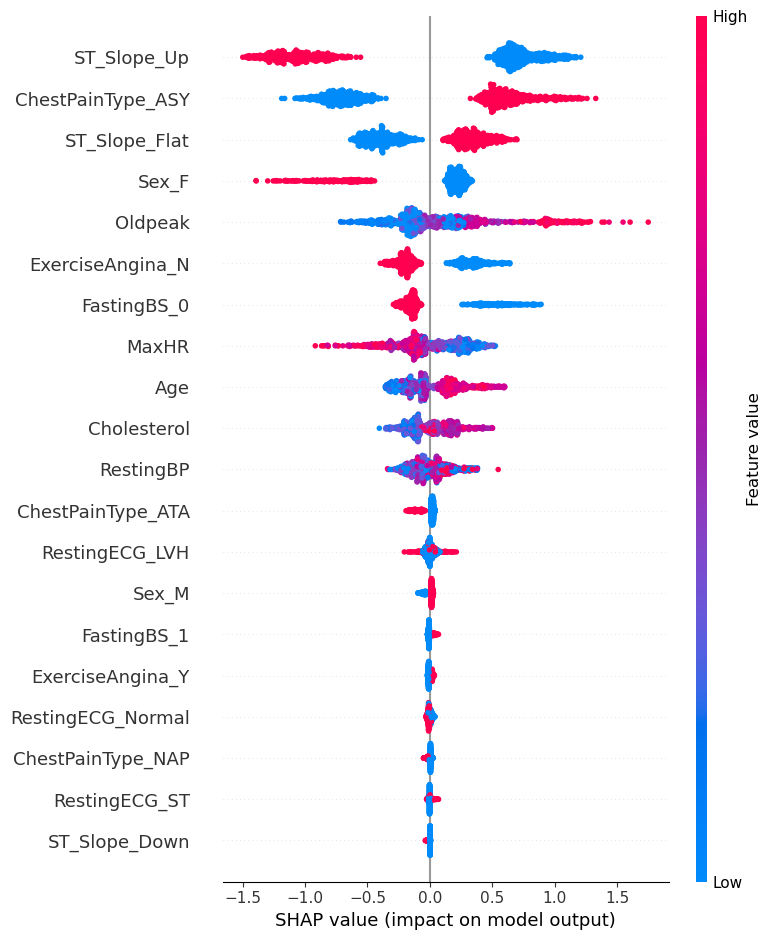

In [67]:
explainer = shap.TreeExplainer(train_pipe.named_steps['model'])
shap_values = explainer.shap_values(preprocessor.transform(X))

shap.summary_plot(shap_values, preprocessor.transform(X),feature_names=features)


<Axes: xlabel='Cholesterol', ylabel='Count'>

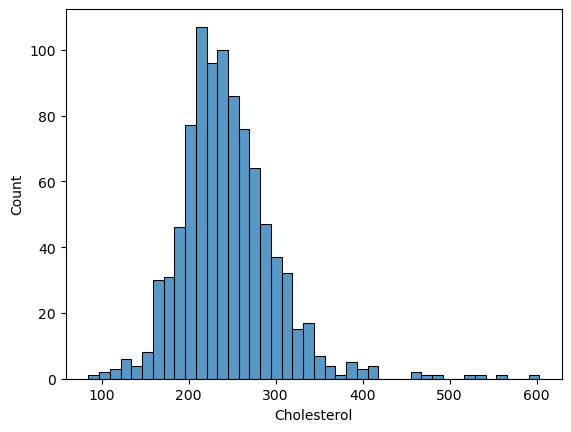

In [70]:
sns.histplot(X['Cholesterol'])